# Лабораторна робота № 8
## Методи кластеризації: K-Means, метод ліктя, коефіцієнт силуета та PCA

**Мета:** навчитися застосовувати алгоритм K-Means, добирати кількість кластерів за допомогою методу ліктя та коефіцієнта силуета; дослідити використання PCA. Додатково — порівняти моделі класифікації на наборі даних про студентів (цей етап збережено з початкової роботи).

**Середовище:** Google Colab або Jupyter Notebook із Python. Для завдання 2 потрібно завантажити набір даних з кагл https://www.kaggle.com/datasets/rabieelkharoua/students-performance-dataset?select=Student_performance_data+_.csv.

**Виконання:** запускайте комірки послідовно, зверху вниз.

## Завдання 1. Кластеризація набору даних Iris

**1.1. Імпорт бібліотек.** Імпортуйте `matplotlib`, `pandas`, `seaborn`, `load_iris`, `KMeans`, `silhouette_score` і `StandardScaler`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

**1.2. Завантаження Iris.** Завантажте Iris та виведіть перші п’ять рядків таблиці з назвами ознак.

In [2]:
iris = load_iris(as_frame=True)
iris_df = iris.data
display(iris_df.head())


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


**1.3. Масштабування та метод ліктя.** Стандартизуйте дані та за допомогою методу ліктя визначте оптимальну кількість кластерів

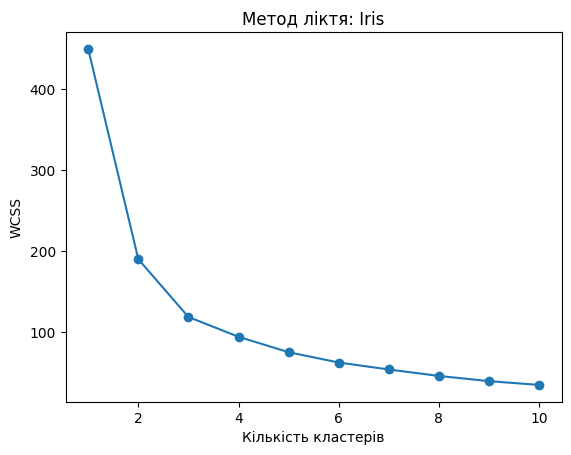

In [3]:
X_iris = iris_df.iloc[:, :3]
scaler_iris = StandardScaler()
X_iris_scaled = scaler_iris.fit_transform(X_iris)

inertias_iris = []
for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_iris_scaled)
    inertias_iris.append(model.inertia_)

plt.plot(range(1, 11), inertias_iris, marker='o')
plt.xlabel('Кількість кластерів')
plt.ylabel('WCSS')
plt.title('Метод ліктя: Iris')
plt.show()


**1.4. Метод силуетів.** Для тих самих трьох ознак Iris обчисліть середній коефіцієнт силуета для 2–10 кластерів і побудуйте графік.

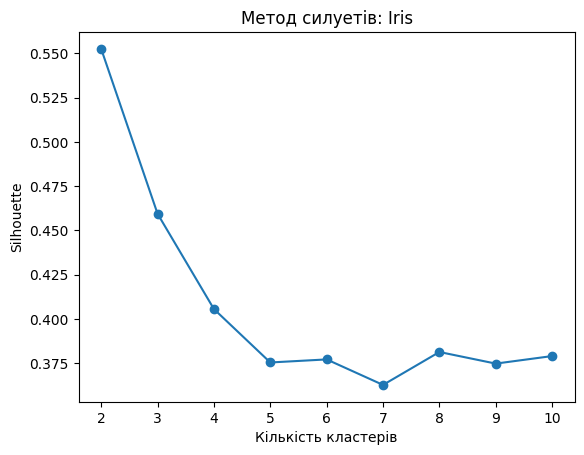

Найкраще K за силуетом: 2


In [4]:
silhouettes_iris = []
for k in range(2, 11):
    labels = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_iris_scaled)
    silhouettes_iris.append(silhouette_score(X_iris_scaled, labels))

plt.plot(range(2, 11), silhouettes_iris, marker='o')
plt.xlabel('Кількість кластерів')
plt.ylabel('Silhouette')
plt.title('Метод силуетів: Iris')
plt.show()
print('Найкраще K за силуетом:', range(2, 11)[silhouettes_iris.index(max(silhouettes_iris))])


**1.5. Фінальна кластеризація та візуалізація.** Побудуйте K-Means для `n_clusters=2`  На площині покажіть перші дві з них та відповідні координати центрів. Це **двовимірне відображення результату кластеризації за трьома ознаками**.

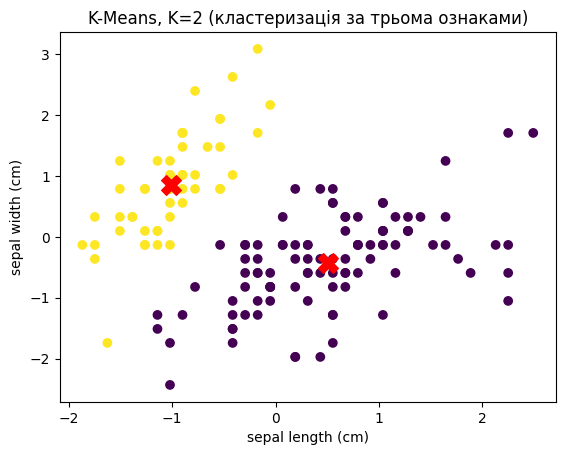

In [5]:
iris_model = KMeans(n_clusters=2, random_state=42, n_init=10)
iris_labels = iris_model.fit_predict(X_iris_scaled)
plt.scatter(X_iris_scaled[:, 0], X_iris_scaled[:, 1], c=iris_labels, cmap='viridis')
plt.scatter(iris_model.cluster_centers_[:, 0], iris_model.cluster_centers_[:, 1],
            c='red', marker='X', s=200)
plt.xlabel(X_iris.columns[0])
plt.ylabel(X_iris.columns[1])
plt.title('K-Means, K=2 (кластеризація за трьома ознаками)')
plt.show()


## Завдання 2. Дослідження даних студентів

Спочатку порівняйте три класифікатори (як у початковій лабораторній роботі), а потім виконайте кластеризацію. **Класифікація та кластеризація — різні задачі:** у класифікації використовується цільова ознака `GradeClass`, а в кластеризації — ні.

**2.1. Імпорт бібліотек для класифікації.** Імпортуйте засоби для поділу даних, добору параметрів, класифікації та оцінювання моделей.

In [6]:
import os
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report


**2.2. Завантаження файлу.** Завантажте набір даних студентів безпосередньо з Kaggle за допомогою `kagglehub`.


In [7]:
import kagglehub
path = kagglehub.dataset_download('rabieelkharoua/students-performance-dataset')


Using Colab cache for faster access to the 'students-performance-dataset' dataset.


**2.3. Перегляд даних.** Прочитайте CSV у DataFrame і перегляньте вміст.

In [8]:
df = pd.read_csv(os.path.join(path, 'Student_performance_data _.csv'))
df.head()


,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


**2.4. Назви стовпців.** Виведіть назви всіх стовпців.

In [9]:
print(df.columns.tolist())


['StudentID', 'Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA', 'GradeClass']


**2.5. Структура таблиці.** Перегляньте типи стовпців і кількість непорожніх значень.

In [10]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(3), int64(12)
memory usage: 280.4 KB


**2.6. Пропущені значення.** Перевірте, чи містить набір даних пропущені значення.

In [11]:
print(df.isna().sum())


StudentID            0
Age                  0
Gender               0
Ethnicity            0
ParentalEducation    0
StudyTimeWeekly      0
Absences             0
Tutoring             0
ParentalSupport      0
Extracurricular      0
Sports               0
Music                0
Volunteering         0
GPA                  0
GradeClass           0
dtype: int64


**2.7. Дублікати.** Обчисліть кількість дублікатів.

In [12]:
print('Дублікати:', df.duplicated().sum())


Дублікати: 0


**2.8. Описова статистика.** Виведіть основні описові статистики.

In [13]:
display(df.describe())


,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
count,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000
mean,2196.500000,16.468645,0.510870,0.877508,1.746237,9.771992,14.541388,0.301421,2.122074,0.383361,0.303512,0.196906,0.157191,1.906186,2.983696
std,690.655244,1.123798,0.499986,1.028476,1.000411,5.652774,8.467417,0.458971,1.122813,0.486307,0.459870,0.397744,0.364057,0.915156,1.233908
min,1001.000000,15.000000,0.000000,0.000000,0.000000,0.001057,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1598.750000,15.000000,0.000000,0.000000,1.000000,5.043079,7.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.174803,2.000000
50%,2196.500000,16.000000,1.000000,0.000000,2.000000,9.705363,15.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,1.893393,4.000000
75%,2794.250000,17.000000,1.000000,2.000000,2.000000,14.408410,22.000000,1.000000,3.000000,1.000000,1.000000,0.000000,0.000000,2.622216,4.000000
max,3392.000000,18.000000,1.000000,3.000000,4.000000,19.978094,29.000000,1.000000,4.000000,1.000000,1.000000,1.000000,1.000000,4.000000,4.000000


**2.9. Підготовка даних для класифікації.** Сформуйте `X` та `y`, прибравши з ознак цільову змінну `GradeClass` і службовий ідентифікатор `StudentID`. Поділіть дані у співвідношенні 80/20 та стандартизуйте ознаки.

In [14]:
X = df.drop(columns=['StudentID', 'GradeClass'])
y = df['GradeClass']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


### 2.10. Класифікація: Random Forest

**Модель Random Forest.** Здійсніть добір гіперпараметрів `GridSearchCV` (5 згорток), виведіть найкращі параметри, середню CV-точність і тестову accuracy. Пошук може тривати довше через велику сітку параметрів.

In [15]:
rf_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    {'n_estimators': [100, 200], 'max_depth': [None, 10], 'min_samples_split': [2, 5]},
    cv=5, scoring='accuracy', n_jobs=-1
)
rf_search.fit(X_train_scaled, y_train)
rf_acc = accuracy_score(y_test, rf_search.predict(X_test_scaled))
print('Найкращі параметри:', rf_search.best_params_)
print('CV accuracy:', round(rf_search.best_score_, 4))
print('Test accuracy:', round(rf_acc, 4))


Найкращі параметри: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 200}
CV accuracy: 0.9211
Test accuracy: 0.9102


### 2.11. Класифікація: Logistic Regression

**Модель Logistic Regression.** Застосуйте `GridSearchCV` до логістичної регресії. Для багатокласової задачі використайте `saga` — `liblinear` у нових версіях sklearn не підтримує багатокласову класифікацію без додаткової обгортки.

In [16]:
lr_search = GridSearchCV(
    LogisticRegression(solver='saga', max_iter=3000, random_state=42),
    {'C': [0.1, 1, 10], 'class_weight': [None, 'balanced']},
    cv=5, scoring='accuracy', n_jobs=-1
)
lr_search.fit(X_train_scaled, y_train)
lr_acc = accuracy_score(y_test, lr_search.predict(X_test_scaled))
print('Найкращі параметри:', lr_search.best_params_)
print('CV accuracy:', round(lr_search.best_score_, 4))
print('Test accuracy:', round(lr_acc, 4))


Найкращі параметри: {'C': 10, 'class_weight': None}
CV accuracy: 0.7951
Test accuracy: 0.7933


### 2.12. Класифікація: Support Vector Machine

**Модель SVM.** Виконайте підбір параметрів SVM та обчисліть CV-точність і тестову accuracy.

In [17]:
svm_search = GridSearchCV(
    SVC(),
    {'C': [0.1, 1, 10], 'kernel': ['linear', 'rbf']},
    cv=5, scoring='accuracy', n_jobs=-1
)
svm_search.fit(X_train_scaled, y_train)
svm_acc = accuracy_score(y_test, svm_search.predict(X_test_scaled))
print('Найкращі параметри:', svm_search.best_params_)
print('CV accuracy:', round(svm_search.best_score_, 4))
print('Test accuracy:', round(svm_acc, 4))


Найкращі параметри: {'C': 10, 'kernel': 'linear'}
CV accuracy: 0.8521
Test accuracy: 0.858


### 2.13. Порівняння результатів

**Порівняння моделей.** Порівняйте тестову точність трьох моделей. Оберіть модель **за найкращою CV-точністю**, а звіт `classification_report` виведіть один раз на тестових даних.

In [18]:
models_results = pd.DataFrame({
    'Model': ['Random Forest', 'Logistic Regression', 'SVM'],
    'CV accuracy': [rf_search.best_score_, lr_search.best_score_, svm_search.best_score_],
    'Test accuracy': [rf_acc, lr_acc, svm_acc]
})
display(models_results.round(4))
best_classifier = max([rf_search, lr_search, svm_search], key=lambda model: model.best_score_)
print('Найкраща модель за CV:', type(best_classifier.best_estimator_).__name__)
print(classification_report(y_test, best_classifier.predict(X_test_scaled)))


,Model,CV accuracy,Test accuracy
0,Random Forest,0.9211,0.9102
1,Logistic Regression,0.7951,0.7933
2,SVM,0.8521,0.8580


Найкраща модель за CV: RandomForestClassifier
              precision    recall  f1-score   support

         0.0       1.00      0.29      0.44        21
         1.0       0.82      0.85      0.84        54
         2.0       0.89      0.95      0.92        78
         3.0       0.89      0.89      0.89        83
         4.0       0.94      0.97      0.96       243

    accuracy                           0.91       479
   macro avg       0.91      0.79      0.81       479
weighted avg       0.91      0.91      0.90       479



### 2.14. Кластеризація даних студентів: метод ліктя

**Метод ліктя для студентів.** Для кластеризації використайте чотири числові ознаки `Age`, `StudyTimeWeekly`, `Absences`, `GPA`. Стандартизуйте їх і побудуйте графік WCSS для 1–10 кластерів.

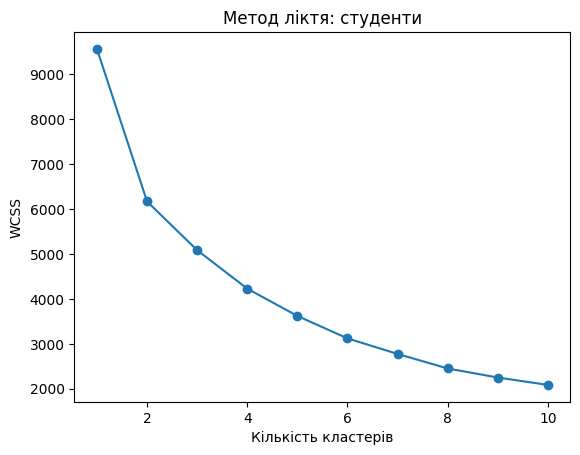

In [19]:
student_features = df[['Age', 'StudyTimeWeekly', 'Absences', 'GPA']]
X_students = StandardScaler().fit_transform(student_features)
wcss_students = []
for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_students)
    wcss_students.append(model.inertia_)
plt.plot(range(1, 11), wcss_students, marker='o')
plt.xlabel('Кількість кластерів')
plt.ylabel('WCSS')
plt.title('Метод ліктя: студенти')
plt.show()


### 2.15. Кластеризація даних студентів: метод силуетів

**Метод силуетів для студентів.** Для тих самих чотирьох ознак побудуйте графік коефіцієнта силуета для 2–10 кластерів.

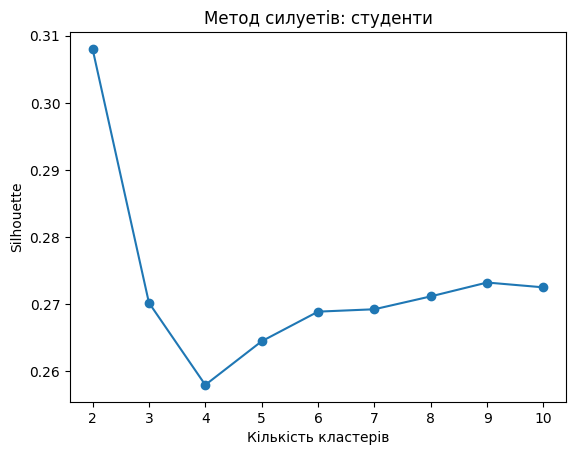

Найкраще K за силуетом: 2


In [20]:
silhouettes_students = []
for k in range(2, 11):
    labels = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_students)
    silhouettes_students.append(silhouette_score(X_students, labels))
plt.plot(range(2, 11), silhouettes_students, marker='o')
plt.xlabel('Кількість кластерів')
plt.ylabel('Silhouette')
plt.title('Метод силуетів: студенти')
plt.show()
print('Найкраще K за силуетом:', range(2, 11)[silhouettes_students.index(max(silhouettes_students))])


### 2.16. Додатковий підхід: PCA та автоматичне визначення точки ліктя

Тут використовується **інший набір ознак**: усі стовпці, крім `StudentID` та `GradeClass`. Після PCA кластеризацію проведемо за вибраними головними компонентами.

**Установлення додаткових пакетів.** За потреби встановіть `kneed` і `yellowbrick` у середовищі ноутбука.

In [21]:
%pip install -q kneed yellowbrick


**Імпорт PCA і KneeLocator.** Імпортуйте `PCA`, `KneeLocator` та `numpy`.

In [22]:
from sklearn.decomposition import PCA
from kneed import KneeLocator
import numpy as np


**Підготовка всіх ознак.** Приберіть `StudentID` і `GradeClass`, залишивши ознаки для PCA.

In [23]:
X_pca_features = df.drop(columns=['StudentID', 'GradeClass'])


**Модель PCA.** Стандартизуйте ознаки, навчіть PCA та знайдіть частку поясненої дисперсії кожної компоненти.

In [24]:
X_pca_scaled = StandardScaler().fit_transform(X_pca_features)
pca = PCA().fit(X_pca_scaled)
explained_variance = pca.explained_variance_ratio_
print('Пояснена дисперсія:', explained_variance.round(4))


Пояснена дисперсія: [0.1525 0.0861 0.0827 0.0807 0.0786 0.0779 0.0763 0.076  0.0744 0.0738
 0.0717 0.0675 0.0018]


**Визначення кількості компонент.** Застосуйте `KneeLocator` до часток поясненої дисперсії. У підписі графіка вказуйте номер компоненти без додавання одиниці.

Кількість компонент за методом ліктя: 2


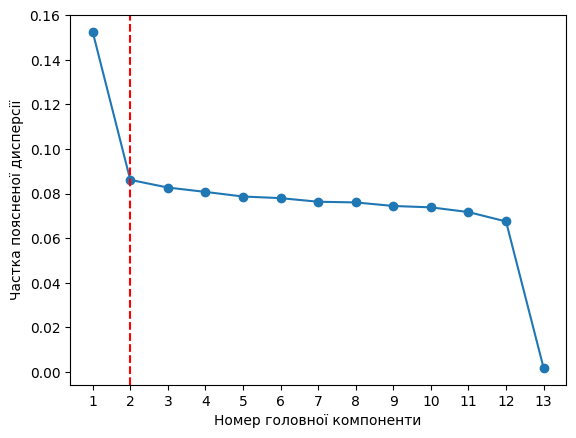

In [25]:
component_numbers = np.arange(1, len(explained_variance) + 1)
knee = KneeLocator(component_numbers, explained_variance, curve='convex', direction='decreasing')
n_components = knee.knee
print('Кількість компонент за методом ліктя:', n_components)
plt.plot(component_numbers, explained_variance, marker='o')
if n_components is not None:
    plt.axvline(n_components, color='red', linestyle='--')
plt.xticks(component_numbers)
plt.xlabel('Номер головної компоненти')
plt.ylabel('Частка поясненої дисперсії')
plt.show()


**Кумулятивна пояснена дисперсія.** На горизонтальній осі має бути **кількість головних компонент** (1, 2, 3, ...), тому індекс масиву для `n_components` дорівнює `n_components - 1`.

**Кумулятивна дисперсія та перетворення PCA.** Побудуйте графік кумулятивної дисперсії та позначте знайдену кількість компонент. Виведіть фактичну частку дисперсії. Перетворіть ознаки через PCA для наступного етапу.

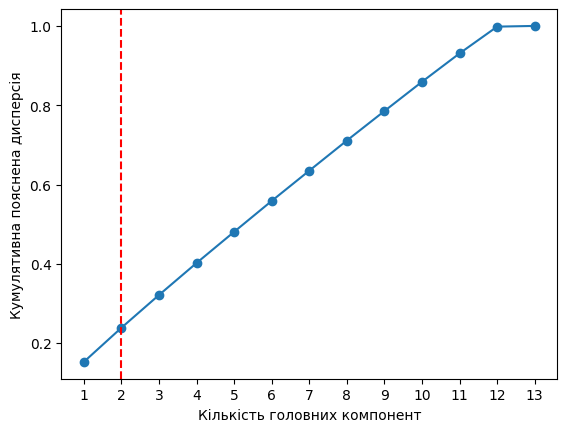

Частка поясненої дисперсії: 0.2386


In [26]:
cumulative_variance = np.cumsum(explained_variance)
if n_components is None:
    n_components = int(np.searchsorted(cumulative_variance, 0.9) + 1)

plt.plot(component_numbers, cumulative_variance, marker='o')
plt.axvline(n_components, color='red', linestyle='--')
plt.xticks(component_numbers)
plt.xlabel('Кількість головних компонент')
plt.ylabel('Кумулятивна пояснена дисперсія')
plt.show()
print('Частка поясненої дисперсії:', round(cumulative_variance[n_components - 1], 4))
X_pca = PCA(n_components=n_components).fit_transform(X_pca_scaled)


Зауваження: кумулятивна пояснена дисперсія — це **частка дисперсії**, а не відсоток «інформативності» даних. Значення потрібно брати з розрахунку, а не задавати наперед (наприклад, 32%).

**Імпорт KElbowVisualizer.** Імпортуйте `KElbowVisualizer` із `yellowbrick.cluster`.

In [27]:
from yellowbrick.cluster import KElbowVisualizer


**Метод ліктя після PCA.** Побудуйте графік `KElbowVisualizer` для K-Means. Для узгодженості з попереднім етапом використайте **дані після PCA**.

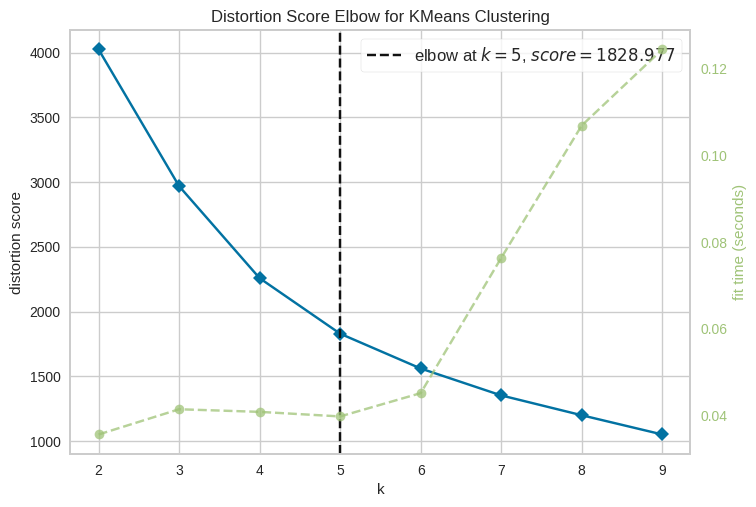

Оптимальне K за KElbowVisualizer: 5


In [28]:
visualizer = KElbowVisualizer(
    KMeans(random_state=42, n_init=10), k=(2, 10)
)
visualizer.fit(X_pca)
visualizer.show()
print('Оптимальне K за KElbowVisualizer:', visualizer.elbow_value_)
